# Detecting Suspected Insider Trading on Polymarket via Account Trust Scores
**Big Data Analytics – Final Project, Group 4** · Muhammet Yildiz, Peyman Aparviz, Orlando Poensgen
**Deliverable:** 2nd delivery (intermediate status)

## Status of this delivery
| Layer | Status | What is in this notebook |
|---|---|---|
| 1. Data Source | working | Gamma API (markets), Data API v2 (trades), positions, Etherscan/Polygon (wallet age) |
| 2. Data Storage | working | raw JSON -> MongoDB, cleaned -> Parquet |
| 3. Analysis | first version | data quality checks, descriptive stats, calibration of the crowd price, first Spark aggregation per wallet |
| 4. Output | first version | plots (market universe, crowd-price calibration) |
| ML / suspicion score | planned | see "Next steps"; label decision already documented in `docs/decisions.md` |

**Research question:** Can suspected informed trading be detected on Polymarket, i.e. are there wallets that systematically enter *against the crowd price* early and win?

> This notebook is the *documentation* of the intermediate state. The same pipeline exists as standalone, resumeable scripts in the repo (`extract/`, `clean/`, `analyze/`, `run_all.py`) – the mapping is shown near the end. Raw API responses are cached in `data/raw/` so re-runs are fast and the data is delivered with the notebook.

## 0. Setup & libraries

In [1]:
# pip install requests pymongo pandas pyarrow pyspark matplotlib
import os, time, json
from pathlib import Path
from datetime import datetime, timezone
import requests
import pandas as pd
import matplotlib.pyplot as plt
from importlib.metadata import version

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_colwidth", 60)

DATA_DIR = Path("data"); RAW_DIR = DATA_DIR / "raw"; RAW_DIR.mkdir(parents=True, exist_ok=True)
REFRESH = False          # True -> force re-download even if cached

# .env support (keys never go into the repo; a manual mini-loader, no extra dependency)
ENV = {}
if Path(".env").exists():
    for line in Path(".env").read_text().splitlines():
        if line.strip() and not line.strip().startswith("#") and "=" in line:
            k, _, v = line.partition("=")
            ENV[k.strip()] = v.strip()
def env(key, default=""):
    return os.environ.get(key, ENV.get(key, default))

# Documentation requirement: list libraries with versions
for lib in ["requests", "pymongo", "pandas", "pyarrow", "pyspark", "matplotlib"]:
    try:
        print(f"{lib:12s} {version(lib)}")
    except Exception:
        print(f"{lib:12s} NOT INSTALLED")

requests     2.34.2
pymongo      4.20.1
pandas       3.1.1
pyarrow      26.0.1
pyspark      4.3.0
matplotlib   3.11.2


In [2]:
# ---- Configuration -------------------------------------------------
GAMMA_URL = "https://gamma-api.polymarket.com"
DATA_URL  = "https://data-api.polymarket.com"      # only /v2/... routes (v1 is retired, see below)
ETHERSCAN_V2 = "https://api.etherscan.io/v2/api"   # Polygonscan is served via the Etherscan unified v2 API (chainid=137)
ETHERSCAN_KEY = env("ETHERSCAN_API_KEY", "")       # DO NOT hardcode your key

MONGO_URI = env("MONGO_URI", "mongodb://localhost:27017")
DB_NAME   = "polymarket"

N_MARKETS = 500          # start small, scale up later (full pull via run_all.py)
N_SAMPLE_MARKETS = 20    # markets for which we pull trades in this delivery
MAX_TRADES_PER_MARKET = 200  # cap per market, keeps API calls and runtime small
WALLET_AGES_TOPN = 50    # wallets to enrich on-chain (free tier is rate limited)
print("Etherscan key present:", bool(ETHERSCAN_KEY))

Etherscan key present: False


## 1. Data Source Layer
### 1.1 Source overview
| # | Source | Type | Content | Key fields |
|---|---|---|---|---|
| 1 | Polymarket Gamma API | REST / JSON | markets, creation dates, resolution | `conditionId`, `question`, `outcomes`, `outcomePrices`, `volumeNum`, `createdAt`, `endDate`, `closedTime` |
| 2 | Polymarket Data API v2 | REST / JSON | trades per market / wallet | `proxy_wallet`, `side`, `price`, `size`, `timestamp`, `outcome_index`, `condition_id` |
| 3 | Etherscan v2 / Polygon (former Polygonscan), chainid 137 | REST / JSON | first on-chain tx of a wallet = wallet age + funding | `timeStamp`, `from`, `to` |

Notes:
* `outcomes`, `outcomePrices` and `clobTokenIds` come as **JSON-encoded strings** ("JSON-in-JSON", a nice argument for the document DB). A resolved market has prices like `["1","0"]`; the index of the `1` is the winning outcome.
* **v1 of the Data API is retired** – `https://data-api.polymarket.com/trades` answers with `{"error": "Data API v1 has been retired", "migration": ".../v2/"}`. Everything uses `/v2/` (all API findings are documented with measurements in `docs/decisions.md`).

In [3]:
def get_json(url, params=None, retries=4, pause=1.0, cache_name=None, refresh=REFRESH):
    """GET -> parsed JSON with retry/backoff AND a disk cache in data/raw/.

    Only retries what can succeed later (429 / 5xx / network errors);
    other 4xx (bad params, retired endpoints) fail immediately so bugs are visible.
    Respects the server's Retry-After header when present.
    """
    cache_path = RAW_DIR / f"{cache_name}.json" if cache_name else None
    if cache_path and cache_path.exists() and not refresh:
        return json.loads(cache_path.read_text())
    for i in range(retries):
        try:
            r = requests.get(url, params=params, timeout=30,
                             headers={"User-Agent": "oracle-of-polygon-student-project/0.2"})
            if r.status_code == 429 or r.status_code >= 500:
                wait = float(r.headers.get("Retry-After", pause * 2 ** i))
                print(f"  {r.status_code}, waiting {wait:.0f}s")
                time.sleep(wait); continue
            r.raise_for_status()          # permanent errors raise here, no pointless retries
            data = r.json()
            if cache_path:
                cache_path.write_text(json.dumps(data, ensure_ascii=False))
            time.sleep(0.2)              # be polite to the API
            return data
        except requests.HTTPError as e:
            print("  permanent error:", e); return None
        except requests.RequestException as e:   # timeouts, connection problems
            print(f"  retry {i+1}/{retries}: {e}")
            time.sleep(pause * 2 ** i)
    return None

def fetch_closed_markets(n, page=100, refresh=REFRESH):
    """Gamma API uses classic limit/offset pagination.

    IMPORTANT: sort by 'volumeNum' (the numeric field), NOT 'volume' -
    that is a STRING field and sorts alphabetically (measured; documented
    in docs/decisions.md). Sorted descending: liquid markets first."""
    cached = RAW_DIR / "markets_raw.json"
    if cached.exists() and not refresh:
        return json.loads(cached.read_text())[:n]
    out, offset = [], 0
    while len(out) < n:
        batch = get_json(f"{GAMMA_URL}/markets",
                         {"closed": "true", "limit": page, "offset": offset,
                          "order": "volumeNum", "ascending": "false"})
        if not batch: break
        out += batch; offset += page
    RAW_DIR.joinpath("markets_raw.json").write_text(json.dumps(out, ensure_ascii=False))
    return out[:n]

markets_raw = fetch_closed_markets(N_MARKETS)
print(len(markets_raw), "markets fetched")
# look at one raw document to understand the structure (truncated)
print(json.dumps(markets_raw[0], indent=2)[:1200] if markets_raw else "no data")

500 markets fetched
{
  "id": "253591",
  "question": "Will Donald Trump win the 2024 US Presidential Election?",
  "conditionId": "0xdd22472e552920b8438158ea7238bfadfa4f736aa4cee91a6b86c39ead110917",
  "slug": "will-donald-trump-win-the-2024-us-presidential-election",
  "resolutionSource": "",
  "endDate": "2024-11-05T12:00:00Z",
  "startDate": "2024-01-04T22:58:00Z",
  "fee": "20000000000000000",
  "image": "https://polymarket-upload.s3.us-east-2.amazonaws.com/will-donald-trump-win-the-2024-us-presidential-election-c83f01bb-5089-4222-9347-3f12673b6a48.png",
  "icon": "https://polymarket-upload.s3.us-east-2.amazonaws.com/will-donald-trump-win-the-2024-us-presidential-election-c83f01bb-5089-4222-9347-3f12673b6a48.png",
  "description": "This market will resolve to \u201cYes\u201d if Donald J. Trump wins the 2024 US Presidential Election. Otherwise, this market will resolve to \u201cNo.\u201d\n\nThe resolution source for this market is the Associated Press, Fox News, and NBC. This marke

### 1.2 Trades per market (Data API v2)
v2 differences that cost us an afternoon (all verified live, see `docs/decisions.md`):
route `/v2/trades`, filter per market via `condition` (not `market`), **cursor pagination** – the `offset` parameter is rejected with an explicit error ("pages are cursor-only"), responses are wrapped in `{data, pagination}`, fields in `snake_case` (`proxy_wallet`, `condition_id`, ...).
Also: `limit` must stay moderate (we use 200; much larger values measurably misbehave), and `outcome_index` is sometimes `999` = "unknown".

Note: trades come newest-first, so a cap per market keeps the *latest* trades (closest to resolution). For the final analysis the full history is pulled by `extract/fetch_trades.py --scope` (one cache file per market = resumeable).

In [4]:
def fetch_trades(condition_id, max_rows=MAX_TRADES_PER_MARKET, page=200):
    """Walk /v2/trades for one market by following pagination.next_cursor until max_rows."""
    out, cursor = [], None
    while len(out) < max_rows:
        # the same filters must be re-sent on every page; the cursor carries only the position
        params = {"condition": condition_id, "limit": page}
        if cursor: params["cursor"] = cursor
        resp = get_json(f"{DATA_URL}/v2/trades", params)
        if not resp: break
        out += resp.get("data", [])
        pg = resp.get("pagination", {})
        if not pg.get("has_more"): break
        cursor = pg.get("next_cursor")
    return out[:max_rows]

trades_raw = []
for m in markets_raw[:N_SAMPLE_MARKETS]:
    cid = m.get("conditionId")
    if not cid: continue
    t = fetch_trades(cid.lower())
    trades_raw += t
    print(f"{m.get('question','?')[:60]:60s} {len(t):5d} trades")
print("total trades:", len(trades_raw))
if trades_raw: print(json.dumps(trades_raw[0], indent=2)[:700])   # inspect the v2 row structure

Will Donald Trump win the 2024 US Presidential Election?       200 trades
Will Kamala Harris win the 2024 US Presidential Election?      200 trades
Will Donald Trump be inaugurated?                              200 trades
Will the Sacramento Kings win the 2025 NBA Finals?             200 trades
MicroStrategy sells any Bitcoin by May 31, 2026?               200 trades
Will Nicolae Ciucă win the 2024 Romanian Presidential electi   200 trades
US forces enter Iran by April 30?                              200 trades
Will Zelenskyy wear a suit before July?                        200 trades
Will any other Republican Politician win the 2024 US Preside   200 trades
Fed decreases interest rates by 50+ bps after January 2026 m   200 trades
Fed increases interest rates by 25+ bps after January 2026 m   200 trades
US x Iran ceasefire extended by April 22, 2026?                200 trades
US x Iran permanent peace deal by June 15, 2026?               200 trades
Will Argentina win the 2026 FIFA World

### 1.3 Wallet age + funding source (independent 2nd source)
Wallet age = timestamp of the first on-chain transaction. Requires a free Etherscan API key in `.env` (`ETHERSCAN_API_KEY=`). Already fetched wallets are cached in `data/raw/wallet_ages.json` and never re-queried (the free tier allows ~5 req/s; thousands of wallets would otherwise take hours).

In [5]:
def wallet_first_tx(address):
    """Ask for exactly ONE transaction sorted ascending = the wallet's first tx."""
    res = get_json(ETHERSCAN_V2, {"chainid": 137, "module": "account", "action": "txlist",
                                  "address": address, "page": 1, "offset": 1, "sort": "asc",
                                  "apikey": ETHERSCAN_KEY})
    if res and res.get("status") == "1" and res.get("result"):
        tx = res["result"][0]
        return {"address": address, "first_tx_ts": int(tx.get("timeStamp", 0)),
                "funding_from": tx.get("from")}
    return {"address": address, "first_tx_ts": None, "funding_from": None}

wallet_age_cache = json.loads((RAW_DIR / "wallet_ages.json").read_text()) \
    if (RAW_DIR / "wallet_ages.json").exists() else {}

wallets = list({t["proxy_wallet"] for t in trades_raw if t.get("proxy_wallet")})
print(len(wallets), "unique wallets in sample")

if ETHERSCAN_KEY:
    todo = [w for w in wallets if w not in wallet_age_cache][:WALLET_AGES_TOPN]
    for w in todo:
        wallet_age_cache[w] = wallet_first_tx(w)
        time.sleep(0.25)                    # stay inside the free-tier rate limit
    (RAW_DIR / "wallet_ages.json").write_text(json.dumps(wallet_age_cache, indent=1))
    known = sum(1 for v in wallet_age_cache.values() if v.get("first_tx_ts"))
    print(f"wallet ages: {known} of {len(wallet_age_cache)} cached wallets have an on-chain history")
else:
    print("No ETHERSCAN_API_KEY in .env -> on-chain enrichment skipped (graceful). "
          "Free key: etherscan.io/apidashboard")

2733 unique wallets in sample
No ETHERSCAN_API_KEY in .env -> on-chain enrichment skipped (graceful). Free key: etherscan.io/apidashboard


### 1.4 Positions per wallet (source 2b)
`/v2/positions` needs a `user` (wallet) or `condition` filter. Per **user** it returns the `{"data": [...]}` wrapper (per condition a plain array – documented inconsistency, handled in the scripts). Positions carry `avg_price`, `entry_cost_usdc`, PnL and status – the backbone of the wallet PnL features in the final delivery. Demonstrated here for the most active wallet in our sample; the batch version is `extract/fetch_positions.py`.

In [6]:
if trades_raw:
    from collections import Counter
    top_w, _ = Counter(t["proxy_wallet"] for t in trades_raw if t.get("proxy_wallet")).most_common(1)[0]
    pos = get_json(f"{DATA_URL}/v2/positions",
                   {"user": top_w, "limit": 100}, cache_name=f"positions_{top_w[:10]}")
    rows = pos.get("data", []) if isinstance(pos, dict) else (pos or [])
    print(f"top wallet {top_w[:16]}... : {len(rows)} positions")
    if rows:
        print(json.dumps(rows[0], indent=2)[:800])

top wallet 0x84571f1bf97a5c... : 0 positions


## 2. Data Storage Layer
**Design:** raw API responses are stored unchanged in **MongoDB** (schema-flexible, JSON-native, re-processable – and every raw doc stays available even when cleaning decisions change). Cleaned and merged data goes to **Parquet** (columnar, efficient for Spark).

| Collection | Content | Unique key |
|---|---|---|
| `markets_raw` | Gamma API documents | `conditionId` |
| `trades_raw` | Data API trades | `transaction_hash` + `token_id` + `proxy_wallet` |
| `wallets_raw` | first-tx info per wallet | `address` |

In [7]:
from pymongo import MongoClient, UpdateOne

def upsert(coll, docs, key_fn):
    """Idempotent insert: re-running the notebook updates existing docs instead of duplicating them."""
    ops = [UpdateOne(key_fn(d), {"$set": d}, upsert=True) for d in docs]
    if ops: coll.bulk_write(ops, ordered=False)

mongo_available = False
try:
    client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=3000)  # short timeout, no hanging
    db = client[DB_NAME]
    client.admin.command("ping")
    mongo_available = True

    upsert(db.markets_raw, markets_raw, lambda d: {"conditionId": d.get("conditionId")})
    upsert(db.trades_raw, trades_raw,
           lambda d: {"transaction_hash": d.get("transaction_hash"), "token_id": d.get("token_id"),
                      "proxy_wallet": d.get("proxy_wallet")})
    upsert(db.wallets_raw,
           [{"address": w, **v} for w, v in wallet_age_cache.items()],
           lambda d: {"address": d["address"]})
    # indexes speed up the typical access paths: trades per market over time, and trades per wallet
    db.trades_raw.create_index([("condition_id", 1), ("timestamp", 1)])
    db.trades_raw.create_index("proxy_wallet")
    print({c: db[c].count_documents({}) for c in ["markets_raw", "trades_raw", "wallets_raw"]})
except Exception as e:
    print("MongoDB not reachable:", type(e).__name__)
    print("Start it with: docker run -d -p 27017:27017 --name oop-mongo mongo:7")
    print("-> notebook continues; raw JSON stays available in data/raw/ (same content, other engine)")

MongoDB not reachable: ServerSelectionTimeoutError
Start it with: docker run -d -p 27017:27017 --name oop-mongo mongo:7
-> notebook continues; raw JSON stays available in data/raw/ (same content, other engine)


In [8]:
# MongoDB aggregation pipeline (runs INSIDE the DB): trades and USD volume per wallet, top 5
if mongo_available:
    pipe = [{"$group": {"_id": "$proxy_wallet",
                        "n": {"$sum": 1},
                        "usd": {"$sum": {"$multiply": ["$size", "$price"]}}}},
            {"$sort": {"usd": -1}}, {"$limit": 5}]
    for d in db.trades_raw.aggregate(pipe):
        print(f"  {d['_id'][:16]}... {d['n']:6d} trades  ${d['usd']:>12,.0f}")
else:
    print("skipped - MongoDB not reachable (see cell above)")

skipped - MongoDB not reachable (see cell above)


## 3. Cleaning & data quality
Checks: completeness, duplicates, ambiguous resolutions (final prices not exactly 1/0), crypto-price markets (excluded), timestamps, and the `outcome_index == 999` API default value.

In [9]:
mk = pd.DataFrame(markets_raw)
tr = pd.DataFrame(trades_raw)
print("markets:", mk.shape, "| trades:", tr.shape)
print("\nMissing values markets (top 10):\n", mk.isna().mean().sort_values(ascending=False).head(10))
print("\nMissing values trades:\n", tr.isna().mean().sort_values(ascending=False).head(10))
if len(tr):
    print("\nDuplicate trades:",
          tr.duplicated(subset=["transaction_hash", "token_id", "proxy_wallet"]).sum())
    print("outcome_index == 999 (unknown):", (pd.to_numeric(tr["outcome_index"], errors="coerce") == 999).sum())

markets: (500, 123) | trades: (4000, 19)

Missing values markets (top 10):
 volume24hr           1.00
mailchimpTag         1.00
category             1.00
gameId               1.00
line                 1.00
eventStartTime       1.00
readyForCron         1.00
umaEndDateIso        0.99
marketMakerAddress   0.98
liquidityAmm         0.97
dtype: float64

Missing values trades:
 proxy_wallet   0.00
side           0.00
token_id       0.00
condition_id   0.00
size           0.00
price          0.00
timestamp      0.00
title          0.00
slug           0.00
icon           0.00
dtype: float64

Duplicate trades: 0
outcome_index == 999 (unknown): 0


In [10]:
def parse_list(x):
    """Gamma returns lists as JSON strings, e.g. '["1","0"]' -> real list."""
    if isinstance(x, list): return x
    try: return json.loads(x)
    except Exception: return None

def winner_index(row):
    """Index of the winning outcome: the one whose final price is exactly 1. Otherwise None (0.5/0.5 tie, cancelled, ...)."""
    p = parse_list(row.get("outcomePrices"))
    if not p: return None
    p = [float(v) for v in p]
    return p.index(1.0) if (max(p) == 1.0 and p.count(1.0) == 1) else None

mk["winner_idx"] = mk.apply(winner_index, axis=1)
mk["resolved_clean"] = mk["winner_idx"].notna()
print("Clearly resolved:", mk["resolved_clean"].mean().round(3))

# exclude crypto-price markets (short-term "up or down" price bets - nobody can
# have inside information about a coin price in 15 minutes, and they flood the feed)
crypto_pat = r"(?i)\b(bitcoin|btc|ethereum|eth|solana|sol|xrp|crypto)\b.*\b(above|below|price|up or down|reach)\b"
mk["is_crypto_price"] = mk["question"].fillna("").str.contains(crypto_pat, regex=True) | \
                        mk["question"].fillna("").str.contains(r"(?i)up.{0,4}down", regex=True)
print("Crypto-price markets:", mk["is_crypto_price"].sum())

mk_clean = mk[mk.resolved_clean & ~mk.is_crypto_price].copy()
mk_clean["conditionId"] = mk_clean["conditionId"].str.lower()
for c in ["createdAt", "endDate", "closedTime"]:
    if c in mk_clean: mk_clean[c] = pd.to_datetime(mk_clean[c], errors="coerce", utc=True, format="ISO8601")
mk_clean["volume_usd"] = pd.to_numeric(mk_clean.get("volumeNum"), errors="coerce")
print("Clean markets:", len(mk_clean))

Clearly resolved: 0.998
Crypto-price markets: 5
Clean markets: 494


/tmp/ipykernel_7998/3080656285.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mk["is_crypto_price"] = mk["question"].fillna("").str.contains(crypto_pat, regex=True) | \


## 4. First descriptive statistics & visualisation

count             494.00
mean       59,026,914.47
std        93,807,965.98
min        18,768,516.96
25%        24,498,780.72
50%        36,219,832.63
75%        64,435,677.49
max     1,531,479,284.50
Name: volume_usd, dtype: float64


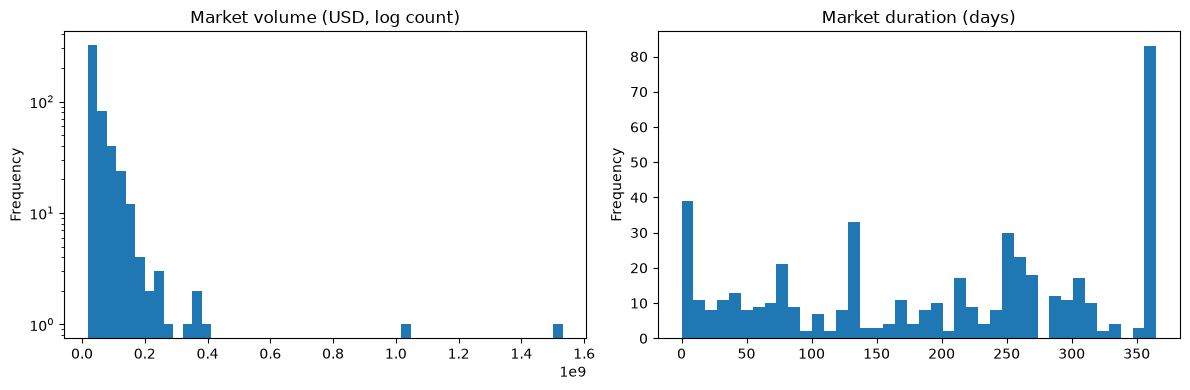

In [11]:
print(mk_clean["volume_usd"].describe())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
mk_clean["volume_usd"].plot.hist(bins=50, log=True, ax=ax[0], title="Market volume (USD, log count)")
if "createdAt" in mk_clean.columns:
    (mk_clean["endDate"] - mk_clean["createdAt"]).dt.days.clip(0, 365) \
        .plot.hist(bins=40, ax=ax[1], title="Market duration (days)")
plt.tight_layout(); plt.show()

### 4.2 Wisdom of the crowd: is the price paid by a trade a calibrated probability?
In a perfectly calibrated market, shares bought at price 0.2 win 20% of the time (the diagonal). We bucket every BUY by price and compare implied probability vs. actual win rate – this is board issue #12 ("wie oft hat die Mehrheit recht"), and it doubles as the **baseline** for the insider story: the better the crowd, the more surprising any wallet that systematically beats it.

            avg_price  win_rate     n
bin                                  
(0.0, 0.1]       0.00      0.00  1593
(0.9, 1.0]       1.00      1.00   819


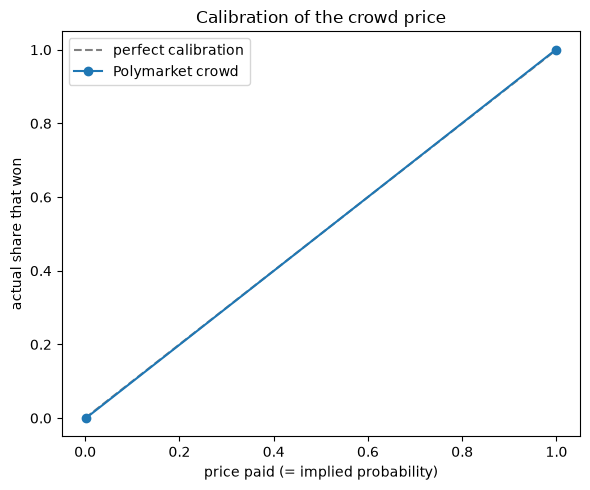

favourites (bought at > 0.5) won in 100.0% of bought trades


In [12]:
t = tr.copy()
if len(t):
    t["condition_id"] = t["condition_id"].str.lower()
    t["price"] = pd.to_numeric(t["price"], errors="coerce")
    t["size"]  = pd.to_numeric(t["size"], errors="coerce")
    t["outcome_index"] = pd.to_numeric(t["outcome_index"], errors="coerce")

    # inner join: give every trade its market's winner; trades outside the clean
    # scope simply drop out of the inner join (that IS the intended filter)
    t = t.merge(mk_clean[["conditionId", "winner_idx"]],
                left_on="condition_id", right_on="conditionId", how="inner").drop(columns=["conditionId"])
    t["won"] = (t["outcome_index"] == t["winner_idx"]).astype(int)   # 1 if the bought outcome won

    buys = t[(t["side"] == "BUY") & (t["outcome_index"] != 999)].copy()   # 999 = outcome unknown
    buys["bin"] = pd.cut(buys["price"], bins=[i/10 for i in range(11)])
    cal = buys.groupby("bin", observed=True) \
             .agg(avg_price=("price", "mean"), win_rate=("won", "mean"), n=("won", "size"))
    print(cal.round(3))

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
    ax.plot(cal["avg_price"], cal["win_rate"], "o-", label="Polymarket crowd")
    ax.set_xlabel("price paid (= implied probability)"); ax.set_ylabel("actual share that won")
    ax.set_title("Calibration of the crowd price"); ax.legend(); plt.tight_layout(); plt.show()

    fav_won = buys.loc[buys["price"] > 0.5, "won"].mean()
    print(f"favourites (bought at > 0.5) won in {fav_won:.1%} of bought trades")

## 5. Export cleaned data to Parquet (Spark interface)

In [13]:
if len(t):
    t[["proxy_wallet", "condition_id", "side", "price", "size", "timestamp",
       "outcome_index", "winner_idx", "won"]] \
        .to_parquet("data/trades_clean.parquet", index=False)
# Parquet cannot store nested list/dict columns -> drop them for the flat file (raw stays in MongoDB)
flat_cols = [c for c in mk_clean.columns
             if not mk_clean[c].map(lambda v: isinstance(v, (list, dict))).any()]
mk_clean[flat_cols].to_parquet("data/markets_clean.parquet", index=False)
print("parquet files:", [p.name for p in Path("data").glob("*.parquet")])

parquet files: ['markets_clean.parquet', 'wallet_features.parquet', 'trades_clean.parquet']


## 6. Processing Layer – first Spark job
Aggregate per wallet: number of trades, volume, win rate, average entry price on winning trades (**contrarian score = 1 - avg price of winners**; high = wallet bought eventual winners cheaply, i.e. against the crowd). Needs `pip install pyspark` – the standalone version of this job is `analyze/spark_wallets.py` (board issue #19).

In [14]:
try:
    from pyspark.sql import SparkSession, functions as F
    spark = SparkSession.builder.appName("polymarket").master("local[*]").getOrCreate()
    spark.sparkContext.setLogLevel("ERROR")

    st = spark.read.parquet("data/trades_clean.parquet")
    st.printSchema()
    print("rows:", st.count())

    wallet_feat = (st.filter(F.col("side") == "BUY")
                      .filter(F.col("outcome_index") != 999)
                      .withColumn("usd", F.col("price") * F.col("size"))
                      .groupBy("proxy_wallet")
                      .agg(F.count("*").alias("n_trades"),
                           F.countDistinct("condition_id").alias("n_markets"),
                           F.sum("usd").alias("volume_usd"),
                           F.avg("won").alias("win_rate"),
                           F.avg(F.when(F.col("won") == 1, 1 - F.col("price")))
                            .alias("contrarian_entry"))
                      .filter("n_trades >= 3")
                      .orderBy(F.desc("contrarian_entry")))
    wallet_feat.show(10, truncate=False)
    spark.stop()
except ImportError:
    print("pyspark not installed -> skip this cell (pip install pyspark); "
          "see analyze/spark_wallets.py")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/20 08:30:21 WARN Utils: Your hostname, Fatih-HP, resolves to a loopback address: 127.0.1.1; using 192.168.0.192 instead (on interface wlo1)
26/11/20 08:30:21 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/fatih/Coding/bigdata/project/.venv/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/20 08:30:21 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


root
 |-- proxy_wallet: string (nullable = true)
 |-- condition_id: string (nullable = true)
 |-- side: string (nullable = true)
 |-- price: double (nullable = true)
 |-- size: double (nullable = true)
 |-- timestamp: long (nullable = true)
 |-- outcome_index: long (nullable = true)
 |-- winner_idx: double (nullable = true)
 |-- won: long (nullable = true)

rows: 4000
+------------------------------------------+--------+---------+------------------+------------------+---------------------+
|proxy_wallet                              |n_trades|n_markets|volume_usd        |win_rate          |contrarian_entry     |
+------------------------------------------+--------+---------+------------------+------------------+---------------------+
|0x01ed5c64d1d8905afd7917d75a5652665f5cca5f|15      |1        |7430.660000000001 |1.0               |0.0050000000000000044|
|0x7d17741e8bf15bc5aff0a4abeea73c214f0e9558|3       |1        |1765.8464000000001|1.0               |0.0050000000000000044|
|0xe8dd77

## 6b. This notebook vs. the repo pipeline

The notebook documents and proves the methods; the same logic lives in resumeable standalone scripts (the "production" pipeline for the team):

| Notebook section | Script (repo) | Board issue |
|---|---|---|
| 1.1 markets | `extract/fetch_markets.py` | #2 |
| 1.2 trades | `extract/fetch_trades.py` (prototype + `--scope` batch with resume) | #3a, #18 |
| 1.3 wallet age | `extract/fetch_wallet_age.py` (with cache) | #5 |
| 1.4 positions | `extract/fetch_positions.py` | #4 |
| 2 storage | `clean/to_mongo.py` | #6 |
| 3 cleaning | `clean/build_parquet.py` | #7 |
| 6 Spark | `analyze/spark_wallets.py` (+ `analyze/features.py` for the full feature table) | #19, #8 |
| 4.2 calibration | `analyze/majority.py` | #12 |
| – orchestration | `run_all.py` (extract -> clean -> analyze, resumeable) | #20 |

Everything at once: `python run_all.py --sample 20`.

## 7. Big Data criteria (draft – to be finalised)
| V | Implication for our project |
|---|---|
| Volume | Polymarket has many thousands of markets and millions of trades (the biggest single market alone has >6,000 trades in just the first 60 pages); we start with a sample and scale the same code up (see `docs/scoping.md` for measured estimates) |
| Velocity | trades arrive continuously; currently batch, streaming would be possible (WebSocket feed) – board issue #15 |
| Variety | JSON from 3 APIs, nested/stringified fields, on-chain data, Mongo vs. Parquet |
| Veracity | ambiguous resolutions, multi-wallet users, wash trading, proxy wallets, `outcome_index=999` defaults |
| Value | detecting informed trading and measuring crowd accuracy |

The four layers map to: APIs -> MongoDB/Parquet -> Spark/ML -> plots & story.

## 8. Next steps (until final delivery)
- [ ] Scale up markets and trades (`run_all.py`, full scope on the team Mongo server – #23)
- [ ] Join wallet age + funding with wallet features; add timing-before-resolution
- [ ] Feature set finalised in `analyze/features.py` (#8): account age, volume, concentration, contrarian entry, repetition, win rate per category
- [ ] ML (#9 #10 #11): IsolationForest + Decision Tree on the heuristic label (decision in `docs/decisions.md`), suspicion score, ranking output
- [ ] Visuals (#13): suspect ranking, contrarian-entry vs payout, timing chart; story
- [ ] Streaming prototype (#15) and multi-wallet clustering (#22) – only if time
- [ ] Kurzbericht (#14) + final documentation

## 9. Sources, data dictionary, versions
**Data sources (all public, accessed Nov 2026):** Gamma API `gamma-api.polymarket.com`, Data API v2 `data-api.polymarket.com/v2`, CLOB API `clob.polymarket.com`, Etherscan unified v2 API (Polygon = chainid 137, former Polygonscan) with free API key. All findings about these APIs are documented in `docs/decisions.md`, the scope in `docs/scoping.md`, team split in `docs/team.md`.

**Data dictionary (Parquet outputs):**
* `markets_clean.parquet` – one row per clean market: `conditionId` (join key), `question`, `winner_idx`, `volume_usd`, `createdAt`, `endDate`, `closedTime` (UTC).
* `trades_clean.parquet` – one row per trade+market join: `proxy_wallet` (Polygon proxy wallet), `condition_id`, `side`, `price` (0–1), `size`, `timestamp` (unix), `outcome_index`, `winner_idx`, `won` (0/1).
* `wallet_ages.json` / parquet – per wallet: `first_tx_ts`, `funding_from` (which address funded it – multi-wallet hint, #22).

**Versions** – printed in the setup cell (requests, pymongo, pandas, pyarrow, pyspark, matplotlib); Python >= 3.10, OS-independent (tested on Windows + Docker Linux).